# Primary Tumour vs Metastasis: Gene Mutations in MSK-MET

- **Author:** Marina Gorikova
- **Date:** November 2026
- **Tools:** Python (pandas, scipy, statsmodels, matplotlib), PyCharm

## About
This project compares gene mutations in **primary tumours** and **metastases**
using the MSK-MET study (about 25,000 patients) from cBioPortal.

**Question:** Which gene mutations are more common after cancer spreads?

## Data
- **Source:** cBioPortal – *MSK MetTropism (MSK, Cell 2021)*, study ID `msk_met_2021`
- **Paper:** Nguyen B, et al. *Cell*, 2022
- https://pmc.ncbi.nlm.nih.gov/articles/PMC9147702/

## Steps
1. Unpack the data
2. Explore the files
3. Choose and load the tables
4. Choose the genes
5. Compare % mutated in primary vs metastasis
6. Statistical test (Fisher's exact test)
7. Repeat within prostate and breast cancer
8. Charts and conclusion

## 1. Unpack the data

In [115]:
import os
import tarfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

archive = "msk_met_2021.tar.gz"           # the file downloaded from cBioPortal
if not os.path.isdir("msk_met_2021"):     # the folder made by unpacking
    print("Unpacking", archive, "...")
    with tarfile.open(archive) as t:
        t.extractall(".", filter="data")
print(os.listdir("msk_met_2021"))

['case_lists', 'data_clinical_patient.txt', 'data_clinical_sample.txt', 'data_cna.txt', 'data_cna_hg19.seg', 'data_gene_panel_matrix.txt', 'data_mutations.txt', 'data_sv.txt', 'data_timeline_diagnosis.txt', 'data_timeline_sequencing.txt', 'data_timeline_status.txt', 'data_timeline_surgery.txt', 'LICENSE', 'meta_clinical_patient.txt', 'meta_clinical_sample.txt', 'meta_cna.txt', 'meta_cna_hg19_seg.txt', 'meta_gene_panel_matrix.txt', 'meta_mutations.txt', 'meta_study.txt', 'meta_sv.txt', 'meta_timeline_diagnosis.txt', 'meta_timeline_sequencing.txt', 'meta_timeline_status.txt', 'meta_timeline_surgery.txt', 'Readme.txt']


## 2. Explore the files
A quick look at the first rows and columns of every data file,
to see what each table contains and decide which ones are needed.

In [116]:
folder="msk_met_2021"
for name in sorted(os.listdir(folder)):
    if name.startswith('data_') and name.endswith('.txt'):
        df=pd.read_csv(os.path.join(folder,name),sep='\t',comment='#',nrows=5,low_memory=False)
        print(f"\n=== {name} ===")
        print(df.iloc[:3, :10])
        print()


=== data_clinical_patient.txt ===
  PATIENT_ID     SEX   RACE  OS_MONTHS   OS_STATUS  AGE_AT_EVIDENCE_OF_METS  \
0  P-0000004  Female  White       3.78  1:DECEASED                    39.66   
1  P-0000015  Female  White      13.90  1:DECEASED                    44.25   
2  P-0000024  Female  White      35.06  1:DECEASED                    59.44   

   AGE_AT_SEQUENCING  AGE_AT_DEATH  AGE_AT_SURGERY  AGE_AT_LAST_CONTACT  
0              39.74         40.06           37.03                  NaN  
1              44.44         45.60           44.42                  NaN  
2              61.33         64.25           61.00                  NaN  


=== data_clinical_sample.txt ===
           SAMPLE_ID PATIENT_ID ORGAN_SYSTEM ONCOTREE_CODE  \
0  P-0000004-T01-IM3  P-0000004       Breast           IDC   
1  P-0000015-T01-IM3  P-0000015       Breast           IDC   
2  P-0000024-T01-IM3  P-0000024  Gynecologic           UEC   

                  SUBTYPE SUBTYPE_ABBREVIATION SAMPLE_TYPE PRIMARY_S

In [117]:
folder = "msk_met_2021"

for name in sorted(os.listdir(folder)):
    if name.startswith("data_") and name.endswith(".txt"):
        n = 0
        with open(os.path.join(folder, name)) as f:
            for line in f:
                if line.startswith("#"):
                    n += 1
                else:
                    break
        print(f"{name:35s} {n} '#' lines")

data_clinical_patient.txt           4 '#' lines
data_clinical_sample.txt            4 '#' lines
data_cna.txt                        0 '#' lines
data_gene_panel_matrix.txt          0 '#' lines
data_mutations.txt                  0 '#' lines
data_sv.txt                         0 '#' lines
data_timeline_diagnosis.txt         0 '#' lines
data_timeline_sequencing.txt        0 '#' lines
data_timeline_status.txt            0 '#' lines
data_timeline_surgery.txt           0 '#' lines


In [118]:
top = pd.read_csv("msk_met_2021/data_clinical_sample.txt",
                  sep="\t", header=None, nrows=5)
top.iloc[:, :3]          # all 5 lines, first 3 columns

,0,1,2
0,#Sample Identifier,Patient Identifier,Organ System
1,#A unique sample identifier.,Identifier to uniquely specify a patient.,Organ System
2,#STRING,STRING,STRING
3,#0,0,1
4,SAMPLE_ID,PATIENT_ID,ORGAN_SYSTEM


In [119]:
def clinical_dictionary(path):
    with open(path) as f:
        lines = [next(f).lstrip("#").rstrip("\n").split("\t") for _ in range(5)]
    return pd.DataFrame({
        "column":      lines[4],   # real column names
        "description": lines[1],   # what the column means
        "type":        lines[2],   # STRING or NUMBER
    })

pd.set_option("display.max_colwidth", 100)
clinical_dictionary("msk_met_2021/data_clinical_sample.txt")

,column,description,type
0,SAMPLE_ID,A unique sample identifier.,STRING
1,PATIENT_ID,Identifier to uniquely specify a patient.,STRING
2,ORGAN_SYSTEM,Organ System,STRING
3,ONCOTREE_CODE,Oncotree Code,STRING
4,SUBTYPE,Subtype,STRING
5,SUBTYPE_ABBREVIATION,Subtype Abbreviation,STRING
6,SAMPLE_TYPE,"The type of sample (i.e., normal, primary, met, recurrence).",STRING
7,PRIMARY_SITE,Text term to describe the organ sub-division in an individual with cancer.,STRING
8,METASTATIC_SITE,The anatomic location to which the cancer has spread.,STRING
9,GENE_PANEL,Gene panel.,STRING


## 3. Choosing the tables
**Question:** Which gene mutations are more common in metastases than in primary tumours?

The question needs two pieces of information for every sample:
1. Is the sample a **primary tumour or a metastasis**? → column `SAMPLE_TYPE` in `data_clinical_sample.txt`
2. **Which genes are mutated** in the sample? → columns `Hugo_Symbol` and `Tumor_Sample_Barcode` in `data_mutations.txt`

No other file contains this information, and both files share the sample ID, so they can be linked.
The other files (copy number, fusions, patients, timelines) describe other things and are not needed for this question.

In [120]:
dictionary = clinical_dictionary("msk_met_2021/data_clinical_sample.txt")
dictionary[dictionary["column"].isin(["SAMPLE_ID", "SAMPLE_TYPE", "CANCER_TYPE"])]

,column,description,type
0,SAMPLE_ID,A unique sample identifier.,STRING
6,SAMPLE_TYPE,"The type of sample (i.e., normal, primary, met, recurrence).",STRING
15,CANCER_TYPE,Cancer Type,STRING


### Mutation table columns used
The mutation file has no description lines, so the column meanings come from the
cBioPortal documentation (File Formats → Mutation Data), which uses the standard MAF format:

- **`Hugo_Symbol`**: official gene name given by the HUGO Gene Nomenclature Committee (e.g. TP53, KRAS)
- **`Tumor_Sample_Barcode`**: ID of the sample the mutation was found in (same as `SAMPLE_ID`)
- **`Variant_Classification`**: type of mutation (e.g. Missense, Nonsense, Frame_Shift, Silent)

Source: https://docs.cbioportal.org/file-formats/

In [121]:
folder = "msk_met_2021/"
muts = pd.read_csv(folder + "data_mutations.txt", sep="\t", low_memory=False,
                   usecols=["Tumor_Sample_Barcode", "Hugo_Symbol", "Variant_Classification"])

In [122]:
print(muts["Hugo_Symbol"].value_counts().head(10), "\n")

Hugo_Symbol
TP53      13367
KRAS       5523
APC        5442
PIK3CA     4163
ARID1A     3206
TERT       3131
KMT2D      2481
PTEN       2339
FAT1       2032
EGFR       1972
Name: count, dtype: int64 



In [123]:
print(muts["Variant_Classification"].value_counts())

Variant_Classification
Missense_Mutation         162019
Nonsense_Mutation          22457
Frame_Shift_Del            20274
Frame_Shift_Ins             7658
Splice_Site                 7628
In_Frame_Del                3937
5'Flank                     2588
In_Frame_Ins                 786
Translation_Start_Site       259
Splice_Region                218
Nonstop_Mutation             151
Intron                       126
3'Flank                      101
5'UTR                         30
Silent                        20
IGR                            1
Name: count, dtype: int64


In [124]:
muts.head()

,Hugo_Symbol,Variant_Classification,Tumor_Sample_Barcode
0,TP53,Missense_Mutation,P-0028912-T01-IM6
1,FYN,Frame_Shift_Ins,P-0028912-T01-IM6
2,KDM5C,Missense_Mutation,P-0028912-T01-IM6
3,KRAS,Missense_Mutation,P-0002794-T02-IM5
4,RAD50,Missense_Mutation,P-0002794-T02-IM5


The most frequently mutated gene is TP53, and most mutations are missense mutations.
This confirms that `Hugo_Symbol` contains gene names and `Variant_Classification` contains mutation types.

In [125]:
folder = "msk_met_2021/"

samples = pd.read_csv(folder + "data_clinical_sample.txt", sep="\t", comment="#",
                      usecols=["SAMPLE_ID", "SAMPLE_TYPE", "CANCER_TYPE"])

muts = pd.read_csv(folder + "data_mutations.txt", sep="\t", low_memory=False,
                   usecols=["Tumor_Sample_Barcode", "Hugo_Symbol", "Variant_Classification"])

print("Sample table:", len(samples), "samples")

Sample table: 25775 samples


In [126]:
print(samples["SAMPLE_TYPE"].value_counts(), "\n")

SAMPLE_TYPE
Primary       15632
Metastasis    10143
Name: count, dtype: int64 



In [127]:
print("Mutation table:", len(muts), "mutations")

Mutation table: 228253 mutations


In [128]:
ids_samples = set(samples["SAMPLE_ID"])
ids_muts = set(muts["Tumor_Sample_Barcode"])

print("Samples in sample table:", len(ids_samples))

Samples in sample table: 25775


In [129]:
print("Samples in mutation table:", len(ids_muts))

Samples in mutation table: 24755


In [130]:
print("Shared by both tables:", len(ids_samples & ids_muts))

Shared by both tables: 24755


The sample table has 25,775 samples (15,632 primary, 10,143 metastasis), as reported by Nguyen et al. (2022).
The mutation table has 228,253 mutations from 24,755 samples, and all 24,755 of these samples are also in the sample table,
so the two tables can be joined by the sample ID.
The remaining 1,020 samples have no mutations detected; they stay in the analysis and are counted as "not mutated".

The chart shows how many primary and metastatic samples there are for the 10 most common cancer types.

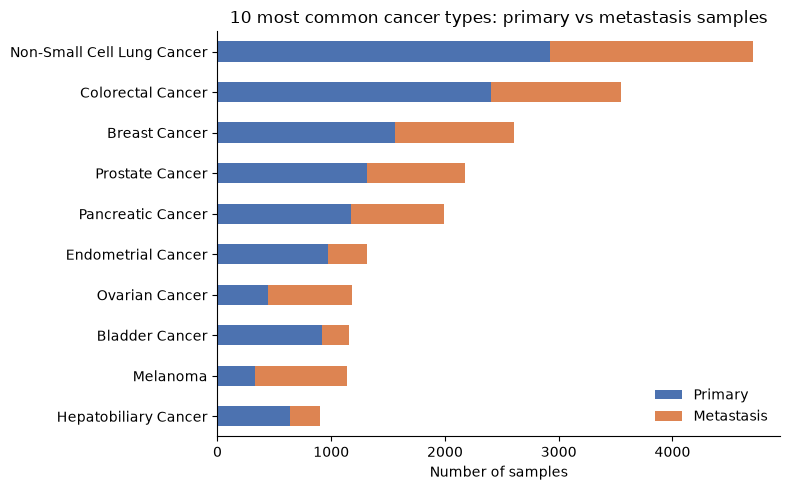

In [131]:
PRIMARY_COLOR = "#4C72B0"
MET_COLOR     = "#DD8452"

counts = pd.crosstab(samples["CANCER_TYPE"], samples["SAMPLE_TYPE"])
counts = counts.loc[counts.sum(axis=1).sort_values().index[-10:]]   # 10 largest cancer types

ax = counts[["Primary", "Metastasis"]].plot(kind="barh", stacked=True, figsize=(8, 5),
                                            color=[PRIMARY_COLOR, MET_COLOR])
ax.set_xlabel("Number of samples")
ax.set_ylabel("")
ax.set_title("10 most common cancer types: primary vs metastasis samples")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/sample_types.png", dpi=200)
plt.show()

## 4. Choosing the genes
We keep only mutations that change the protein (missense, nonsense, frameshift, in-frame, splice site, etc.)
and remove mutations outside the protein-coding part (5'Flank, intron, UTR, silent).
Then we count, for each gene, the percentage of samples with at least one mutation.

In [132]:
protein_changing = ["Missense_Mutation", "Nonsense_Mutation", "Frame_Shift_Del",
                    "Frame_Shift_Ins", "Splice_Site", "In_Frame_Del", "In_Frame_Ins",
                    "Translation_Start_Site", "Nonstop_Mutation"]

muts = muts[muts["Variant_Classification"].isin(protein_changing)]
print("Protein-changing mutations:", len(muts))

gene_freq = (muts.groupby("Hugo_Symbol")["Tumor_Sample_Barcode"].nunique()
             / len(samples) * 100).round(1)
gene_freq.sort_values(ascending=False).head(15)

Protein-changing mutations: 225169


Hugo_Symbol
TP53      48.3
KRAS      21.1
APC       14.1
PIK3CA    13.9
ARID1A     9.8
PTEN       6.9
KMT2D      6.8
EGFR       6.3
BRAF       6.0
ATM        5.7
FAT1       5.7
CDKN2A     5.5
PTPRT      5.5
NF1        5.4
SMAD4      5.3
Name: Tumor_Sample_Barcode, dtype: float64

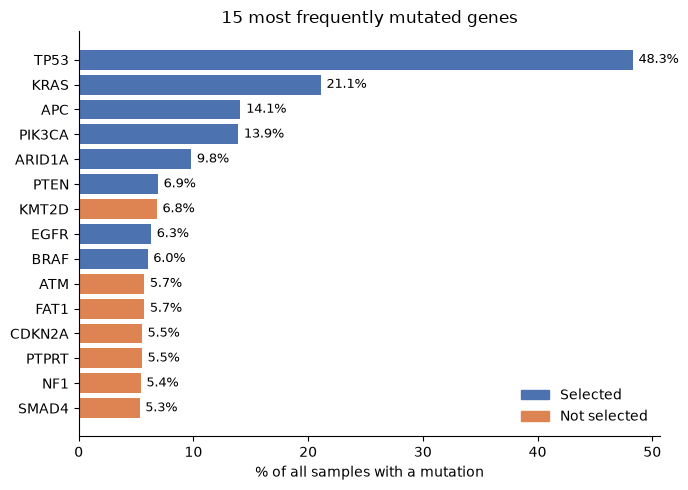

In [133]:
PRIMARY_COLOR = "#4C72B0"   # blue
MET_COLOR     = "#DD8452"   # orange

# Top 15 genes, smallest at the bottom so the largest is on top
top15 = gene_freq.sort_values(ascending=False).head(15).sort_values()
genes_selected = ["TP53", "KRAS", "APC", "PIK3CA", "ARID1A", "PTEN", "EGFR", "BRAF"]

# Blue = selected, orange = not selected
colors = [PRIMARY_COLOR if g in genes_selected else MET_COLOR for g in top15.index]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top15.index, top15.values, color=colors)

# % label next to each bar
for i, v in enumerate(top15.values):
    ax.text(v + 0.5, i, f"{v}%", va="center", fontsize=9)

# Legend explaining the colours
ax.legend(handles=[Patch(color=PRIMARY_COLOR, label="Selected"),
                   Patch(color=MET_COLOR, label="Not selected")],
          frameon=False, loc="lower right")

ax.set_xlabel("% of all samples with a mutation")
ax.set_title("15 most frequently mutated genes")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/top15_genes.png", dpi=200)
plt.show()

**Genes selected:**
- **TP53, KRAS, APC, PIK3CA, ARID1A, PTEN, EGFR, BRAF**: among the most frequently mutated genes
  in this dataset, and well-known cancer genes
- **AR, ESR1**: reported by Nguyen et al. (2022) as much more frequent in metastases
  (prostate and breast cancer), linked to hormone therapy

**Genes not selected:**
- **KMT2D, KMT2C, FAT1**: very large genes that collect many random mutations, harder to interpret
- **TERT**: its mutations are mostly in the promoter (5'Flank), which we removed

All selected genes are on every version of the MSK-IMPACT panel (341, 410 and 468 genes),
so every sample was tested for them.

## 5. How often is each gene mutated in primary tumours vs metastases?
For each selected gene, every sample is marked as mutated (1) or not mutated (0).
Then we calculate the percentage of mutated samples in each group.

In [134]:
genes = ["TP53", "KRAS", "APC", "PIK3CA", "ARID1A", "PTEN",
         "EGFR", "BRAF", "AR", "ESR1"]

table = samples.copy()                     # one row per sample

for gene in genes:
    mutated_samples = muts.loc[muts["Hugo_Symbol"] == gene, "Tumor_Sample_Barcode"]
    table[gene] = table["SAMPLE_ID"].isin(mutated_samples).astype(int)

table.head()

,SAMPLE_ID,SAMPLE_TYPE,CANCER_TYPE,TP53,KRAS,APC,PIK3CA,ARID1A,PTEN,EGFR,BRAF,AR,ESR1
0,P-0000004-T01-IM3,Primary,Breast Cancer,1,0,0,0,0,0,0,0,0,0
1,P-0000015-T01-IM3,Metastasis,Breast Cancer,1,0,0,1,0,0,0,0,0,1
2,P-0000024-T01-IM3,Metastasis,Endometrial Cancer,0,0,0,0,1,1,0,0,0,0
3,P-0000025-T02-IM5,Metastasis,Endometrial Cancer,1,0,0,1,0,0,0,0,0,0
4,P-0000026-T01-IM3,Metastasis,Endometrial Cancer,1,0,0,1,0,0,0,0,0,0


In [135]:
pct = table.groupby("SAMPLE_TYPE")[genes].mean() * 100
pct = pct.T.round(1)                                   # genes as rows
pct["difference"] = pct["Metastasis"] - pct["Primary"]
pct.sort_values("difference", ascending=False)

SAMPLE_TYPE,Metastasis,Primary,difference
TP53,51.4,46.3,5.1
BRAF,7.2,5.2,2.0
ESR1,2.7,1.7,1.0
AR,2.8,2.6,0.2
EGFR,6.4,6.3,0.1
PTEN,5.9,7.6,-1.7
APC,13.1,14.8,-1.7
ARID1A,8.4,10.7,-2.3
KRAS,19.3,22.3,-3.0
PIK3CA,11.8,15.2,-3.4


Across all cancer types, TP53 shows the largest increase in metastases (51.4% vs 46.3%).
Note: this combines all cancer types, which can be misleading (e.g. AR is only relevant
in prostate cancer). Section 7 repeats the comparison within single cancer types.

## 6. Statistical test
Fisher's exact test checks whether a difference could be due to chance.
Because we test 10 genes, a result counts as significant if p < 0.005 (0.05 / 10, Bonferroni correction).

In [136]:
from scipy.stats import fisher_exact

def test_genes(df):
    met = df[df["SAMPLE_TYPE"] == "Metastasis"]
    pri = df[df["SAMPLE_TYPE"] == "Primary"]
    rows = []
    for gene in genes:
        a, b = met[gene].sum(), len(met) - met[gene].sum()   # metastasis: mutated, not
        c, d = pri[gene].sum(), len(pri) - pri[gene].sum()   # primary: mutated, not
        p = fisher_exact([[a, b], [c, d]])[1]
        rows.append([gene, round(100*c/len(pri), 1), round(100*a/len(met), 1), p])
    res = pd.DataFrame(rows, columns=["gene", "% primary", "% metastasis", "p_value"])
    res["significant"] = res["p_value"] < 0.05 / len(genes)
    return res.sort_values("p_value")

test_genes(table)

,gene,% primary,% metastasis,p_value,significant
0,TP53,46.3,51.4,5.969433e-16,True
3,PIK3CA,15.2,11.8,5.969514e-15,True
7,BRAF,5.2,7.2,1.266162e-10,True
4,ARID1A,10.7,8.4,1.903470e-09,True
1,KRAS,22.3,19.3,4.683560e-09,True
9,ESR1,1.7,2.7,4.440147e-08,True
5,PTEN,7.6,5.9,4.946080e-08,True
2,APC,14.8,13.1,2.331888e-04,True
8,AR,2.6,2.8,4.076260e-01,False
6,EGFR,6.3,6.4,7.730868e-01,False


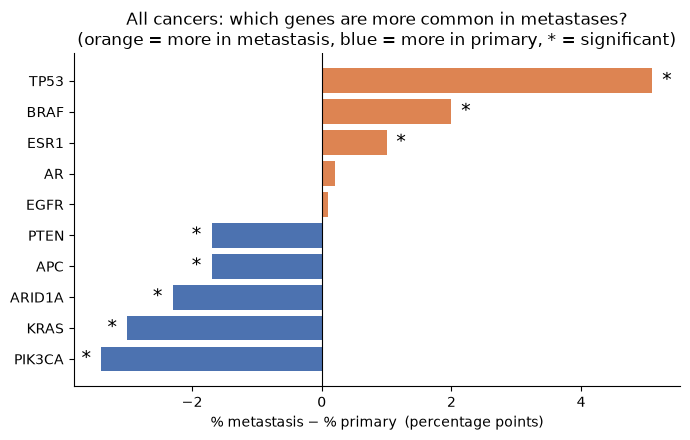

In [137]:
res = test_genes(table)
res["difference"] = res["% metastasis"] - res["% primary"]
res = res.sort_values("difference")
colors = [MET_COLOR if d > 0 else PRIMARY_COLOR for d in res["difference"]]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(res["gene"], res["difference"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)                  # line at zero
for i, (d, sig) in enumerate(zip(res["difference"], res["significant"])):
    if sig:
        ax.text(d + (0.15 if d > 0 else -0.15), i, "*", va="center",
                ha="left" if d > 0 else "right", fontsize=14)
ax.set_xlabel("% metastasis − % primary  (percentage points)")
ax.set_title("All cancers: which genes are more common in metastases?\n"
             "(orange = more in metastasis, blue = more in primary, * = significant)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/difference_all_cancers.png", dpi=200)
plt.show()

Across all cancers, 8 of 10 genes differ significantly. TP53, BRAF and ESR1 are more common in metastases,
while PIK3CA, KRAS, ARID1A, PTEN and APC appear more common in primary tumours.
AR shows no difference (2.6% vs 2.8%). These pooled results partly reflect which cancer types
are sampled more often as metastases, so we look within single cancer types next.

## 7. Within one cancer type
Different cancers have different mutations, so mixing them can mislead.
We repeat the test for prostate and breast cancer.

In [138]:
print("Prostate cancer")
display(test_genes(table[table["CANCER_TYPE"] == "Prostate Cancer"]))

print("Breast cancer")
display(test_genes(table[table["CANCER_TYPE"] == "Breast Cancer"]))

Prostate cancer


,gene,% primary,% metastasis,p_value,significant
8,AR,1.1,9.1,4.271026e-19,True
0,TP53,21.2,35.6,2.722816e-13,True
2,APC,5.4,9.7,2.208740e-04,True
5,PTEN,7.0,9.5,3.581084e-02,False
3,PIK3CA,3.8,5.1,1.609880e-01,False
6,EGFR,0.9,0.6,4.627768e-01,False
7,BRAF,1.9,2.2,6.424992e-01,False
4,ARID1A,2.1,2.4,6.592743e-01,False
1,KRAS,0.9,0.8,1.000000e+00,False
9,ESR1,0.3,0.2,1.000000e+00,False


Breast cancer


,gene,% primary,% metastasis,p_value,significant
9,ESR1,2.1,14.7,1.339928e-34,True
0,TP53,35.2,42.8,8.023482e-05,True
2,APC,0.6,2.5,1.095927e-04,True
3,PIK3CA,38.9,35.0,4.319067e-02,False
4,ARID1A,5.0,6.5,1.176611e-01,False
1,KRAS,0.6,1.1,1.923052e-01,False
5,PTEN,7.3,6.3,3.448207e-01,False
6,EGFR,1.0,1.4,3.615676e-01,False
7,BRAF,0.4,0.4,1.000000e+00,False
8,AR,1.0,1.0,1.000000e+00,False


Within single cancer types the picture is clearer:
- **Prostate cancer:** AR (1.1% → 9.1%), TP53 (21.2% → 35.6%) and APC (5.4% → 9.7%) are significantly more common in metastases.
- **Breast cancer:** ESR1 (2.1% → 14.7%), TP53 (35.2% → 42.8%) and APC (0.6% → 2.5%) are significantly more common in metastases.

AR was not significant across all cancers but is the strongest result in prostate cancer,
which shows why comparing within one cancer type matters.

## 8. Charts
Mutation frequency in primary tumours vs metastases for prostate and breast cancer.
Stars mark significant differences (p < 0.005).

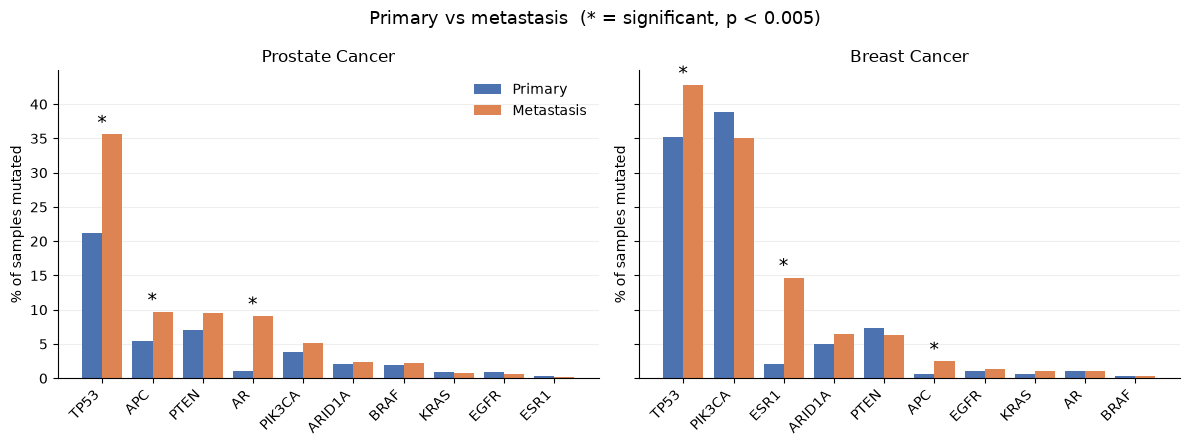

In [139]:
PRIMARY_COLOR = "#4C72B0"   # medium blue
MET_COLOR     = "#DD8452"   # medium orange

def bar_chart(cancer, ax):
    # 1. Test the genes in this cancer type
    res = test_genes(table[table["CANCER_TYPE"] == cancer])
    res = res.sort_values("% metastasis", ascending=False)

    # 2. Draw the bars: primary on the left, metastasis on the right
    x = np.arange(len(res))
    ax.bar(x - 0.2, res["% primary"], 0.4, label="Primary", color=PRIMARY_COLOR)
    ax.bar(x + 0.2, res["% metastasis"], 0.4, label="Metastasis", color=MET_COLOR)

    # 3. Put a star above significant genes
    tops = res[["% primary", "% metastasis"]].max(axis=1)
    for i, (sig, top) in enumerate(zip(res["significant"], tops)):
        if sig:
            ax.text(i, top + 0.8, "*", ha="center", fontsize=14)

    # 4. Labels and style
    ax.set_xticks(x, res["gene"], rotation=45, ha="right")
    ax.set_ylabel("% of samples mutated")
    ax.set_title(cancer, fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#EEEEEE")
    ax.set_axisbelow(True)

# Two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
bar_chart("Prostate Cancer", axes[0])
bar_chart("Breast Cancer", axes[1])
axes[0].legend(frameon=False)
fig.suptitle("Primary vs metastasis  (* = significant, p < 0.005)", fontsize=13)
plt.tight_layout()
plt.savefig("figures/bar_prostate_breast.png", dpi=200)
plt.show()

## Conclusion
- **TP53** was more often mutated in metastases across all cancers (51.4% vs 46.3%),
  and also within prostate (35.6% vs 21.2%) and breast cancer (42.8% vs 35.2%).
- The largest differences were **AR** in prostate cancer (9.1% vs 1.1%) and **ESR1** in breast cancer
  (14.7% vs 2.1%). This matches Nguyen et al. (2022) and is likely caused by hormone therapy,
  which selects for these mutations.
- Comparing all cancers together can hide or distort results (e.g. AR), so comparisons
  should be made within single cancer types.

**Limitations:**
- Primary and metastatic samples come from different patients, not the same tumour over time.
- Treatment may cause some of the differences.
- Only genes on the MSK-IMPACT panel were tested, and only mutations (no copy number or fusions).
- Only two cancer types were analysed in detail.